# 2階微分方程式の解法
このノートでは、2階の微分方程式（＝2次のシステム）を数値的に解く練習を行います。

- 2階の微分方程式を1階の連立方程式に直す
- 単振動をオイラー法と4次のルンゲクッタ法で解き、時間変化と相図を描く
- 刻み幅を変えて、2つの方法の違いを比べる
- ローレンツモデルを解いて、カオスのふるまいを観察する
- 応用として、ばねダンパ系のステップ応答と、逆振り子の反り返り・安定化を扱う

`TODO` と書かれた部分は、自分で考えて埋めてください。
前回までと違い、今回は最初から **関数の中の for 文** を書いてもらいます。
1ステップずつ配列に代入する練習は省略しますので、前回のノートを見返しながら進めてかまいません。

## 1. 2階微分方程式を1階の連立方程式に直す

これまで扱ってきたのは、未知数が1つだけの
$$
\frac{dx}{dt}=f(t, x)
$$
という形でした。今回は、2階微分を含む運動方程式
$$
m\ddot{x} + kx = 0
$$
のような式を数値的に解きます。

このままでは前回の方法が使えないので、**新しい変数を導入して1階の形に直します**。
速度 $v=\dot{x}$ を新しい変数として定義すると、
$$
\frac{dx}{dt}=v, \qquad \frac{dv}{dt}=-\frac{k}{m}x
$$
という、未知数が2つの1階の連立方程式になります。

一般に $m$ 階の微分方程式
$$
\frac{d^{m}x}{dt^{m}}=f\left(t, x, \dot{x}, \ddot{x}, \dots, x^{(m-1)}\right)
$$
は、$x_1=x,\; x_2=\dot{x},\; \dots,\; x_m=x^{(m-1)}$ と置けば、
$m$ 次元ベクトル $\boldsymbol{x}=(x_1, x_2, \dots, x_m)^{\mathsf{T}}$ に対する
$$
\frac{d\boldsymbol{x}}{dt}=\boldsymbol{f}(t, \boldsymbol{x})
$$
という1階の形に必ず書き直せます。

### 1.1 ベクトルになったときの更新式

連立1階微分方程式
$$
\frac{d\boldsymbol{x}}{dt}=\boldsymbol{f}(t, \boldsymbol{x})
$$
を解くには、**各成分 $x_i$ についてスカラーのときと同じ計算をすれば大丈夫です**。

オイラー法は
$$
x_{i,n+1}=x_{i,n}+f_i\left(t_n, x_{1,n}, \dots, x_{m,n}\right)\Delta t
$$
4次のルンゲクッタ法は
$$
k_{i,1}=\Delta t\, f_i\left(t_n, x_{1,n}, \dots, x_{m,n}\right),\\
k_{i,2}=\Delta t\, f_i\left(t_n+\frac{\Delta t}{2}, x_{1,n}+\frac{k_{1,1}}{2}, \dots, x_{m,n}+\frac{k_{m,1}}{2}\right),\\
k_{i,3}=\Delta t\, f_i\left(t_n+\frac{\Delta t}{2}, x_{1,n}+\frac{k_{1,2}}{2}, \dots, x_{m,n}+\frac{k_{m,2}}{2}\right),\\
k_{i,4}=\Delta t\, f_i\left(t_n+\Delta t, x_{1,n}+k_{1,3}, \dots, x_{m,n}+k_{m,3}\right)
$$
を計算して、
$$
x_{i,n+1}=x_{i,n}+\frac{1}{6}\left(k_{i,1}+2k_{i,2}+2k_{i,3}+k_{i,4}\right)
$$
と更新します。

**ここが今回いちばん間違えやすいところです。**
$k_{i,2}$ を計算するとき、$i$ 番目の成分だけでなく **すべての成分を $k_{\cdot,1}$ の分だけ進めた点** で右辺を評価します。
つまり $x$ の $k_2$ を求めるのに $v$ の $k_1$ が必要になります。

$\boldsymbol{x}=(x, v)$ の場合を成分で書き下すと、次のようになります。
$$
k_{1x}=\Delta t\, f_x(t_n, x_n, v_n), \qquad k_{1v}=\Delta t\, f_v(t_n, x_n, v_n),\\
k_{2x}=\Delta t\, f_x\left(t_n+\frac{\Delta t}{2}, x_n+\frac{k_{1x}}{2}, v_n+\frac{k_{1v}}{2}\right),\\
k_{2v}=\Delta t\, f_v\left(t_n+\frac{\Delta t}{2}, x_n+\frac{k_{1x}}{2}, v_n+\frac{k_{1v}}{2}\right)
$$
（$k_3$, $k_4$ も同様です）

## 2. 単振動のシミュレーション

ばね定数 $k$ のばねにつながれた質量 $m$ の質点を考えます。減衰のない、もっとも基本的な単振動
$$
m\ddot{x}+kx=0
$$
を扱います。

1章のとおり、速度 $v=\dot{x}$ を導入して
$$
\frac{dx}{dt}=v, \qquad \frac{dv}{dt}=-\frac{k}{m}x
$$
として解きます。プログラムでは、位置を入れる配列 `x` と速度を入れる配列 `v` を別々に用意し、各時刻の値を順番に保存していきます。

以下では $m=1.0$, $k=1.0$, $x(0)=1.0$, $v(0)=0.0$ とします。
このとき解析解は $x(t)=\cos t$, $v(t)=-\sin t$ なので、答え合わせができます。

### 2.1 オイラー法で時間変化と相図を描いてみる

まずはオイラー法で単振動を計算します。
横軸を時間とした $x(t)$, $v(t)$ のグラフに加えて、横軸を位置 $x$、縦軸を速度 $v$ とした **相図** も描きます。

相図は、システムの状態 $(x, v)$ が時間とともにどう動いたかを描いた図です。
今回の単振動では、解析解は原点を中心とする楕円（今回の条件では半径1の円）になります。

TODO は関数の中の for 文 1 か所です。

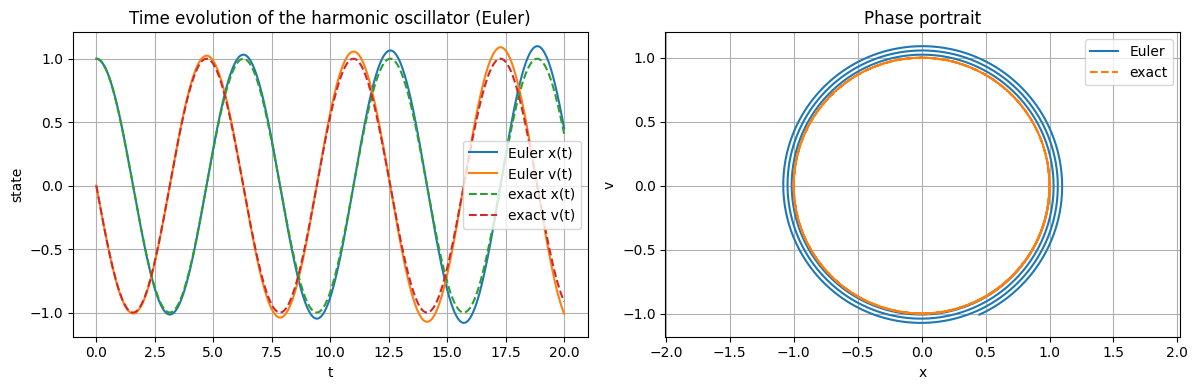

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# 単振動の右辺 dx/dt = v
def func_dx(t, x, v, m, k_spring):
    return v


# 単振動の右辺 dv/dt = -(k/m) * x
def func_dv(t, x, v, m, k_spring):
    return -(k_spring / m) * x


# 単振動をオイラー法で解く関数
def euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    # 引数　m: 質量, k_spring: ばね定数, x0: 初期位置, v0: 初期速度, dt: 時間刻み幅, T: 総時間
    n_steps = round(T / dt)  # 何回時間を進めるかを決める
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)  # 時刻 t を並べた配列を作る
    x = np.zeros(n_steps + 1)  # 位置 x の時間発展を入れる配列を 0 で初期化する
    v = np.zeros(n_steps + 1)  # 速度 v の時間発展を入れる配列を 0 で初期化する

    x[0] = x0  # 初期位置
    v[0] = v0  # 初期速度

    for n in range(n_steps):
        # TODO: オイラー法で x[n+1] と v[n+1] を計算してください
        # ヒント: 右辺は func_dx(t[n], x[n], v[n], m, k_spring) のように呼び出せます
        #         x と v の2つとも更新する必要があります
        #         注意: ばね定数の変数名は k_spring です（ k ではありません ）
        dxdt = func_dx(t[n], x[n], v[n], m, k_spring)
        dvdt = func_dv(t[n], x[n], v[n], m, k_spring)

        # 2. オイラー法の公式に従って次のステップの値を同時に更新
        x[n + 1] = x[n] + dt * dxdt
        v[n + 1] = v[n] + dt * dvdt


    return t, x, v  # 時刻 t と位置 x と速度 v を返す（3つの配列を同時に返せます）


# 解析解 x(t), v(t) を返す関数
def exact_oscillator_x(t, m, k_spring, x0, v0):
    omega = np.sqrt(k_spring / m)
    return x0 * np.cos(omega * t) + (v0 / omega) * np.sin(omega * t)


def exact_oscillator_v(t, m, k_spring, x0, v0):
    omega = np.sqrt(k_spring / m)
    return -x0 * omega * np.sin(omega * t) + v0 * np.cos(omega * t)


# ここから具体的な条件を設定する
m = 1.0  # 質量
k_spring = 1.0  # ばね定数
x0 = 1.0  # 初期位置
v0 = 0.0  # 初期速度
dt = 0.01  # 時間刻み幅
T = 20.0  # 総時間

# オイラー法で単振動の時間発展を計算する
t, x, v = euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)

# 解析解を計算する
x_exact = exact_oscillator_x(t, m, k_spring, x0, v0)
v_exact = exact_oscillator_v(t, m, k_spring, x0, v0)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(t, x, label="Euler x(t)")
plt.plot(t, v, label="Euler v(t)")
plt.plot(t, x_exact, label="exact x(t)", linestyle="dashed")
plt.plot(t, v_exact, label="exact v(t)", linestyle="dashed")
plt.xlabel("t")
plt.ylabel("state")
plt.title("Time evolution of the harmonic oscillator (Euler)")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, v, label="Euler")
plt.plot(x_exact, v_exact, label="exact", linestyle="dashed")
plt.xlabel("x")
plt.ylabel("v")
plt.title("Phase portrait")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

上のプログラムの補足説明です。

- 更新するのは `x[n+1]` と `v[n+1]` の2つです。片方だけ更新しても動いてしまうので注意してください
- `v[n+1]` を先に計算して、その値を `x[n+1]` の計算に使うと、実は別の解法（半陰解法）になります。
  今回は両方とも時刻 $t_n$ の値 `x[n]`, `v[n]` から計算してください
- 相図のグラフで `plt.axis("equal")` としているのは、縦横の縮尺をそろえて円が円に見えるようにするためです

グラフが描けたら、相図の形を確認してください。
解析解は閉じた円になりますが、オイラー法の結果はどうなっているでしょうか。

### 2.2 4次のルンゲクッタ法で解いてみる

同じ単振動を、今度は4次のルンゲクッタ法で解きます。
1.1 で確認したとおり、$k_1$ から $k_4$ を **$x$ と $v$ の両方について** 計算する必要があります。

TODO は2か所です。

1. `euler_oscillator`: 2.1 で書いた中身をそのまま写してください
2. `runge_kutta_oscillator`: 4次のルンゲクッタ法を新しく書いてください

書けたら、オイラー法・ルンゲクッタ法・解析解の3つを同じグラフで比べてみましょう。

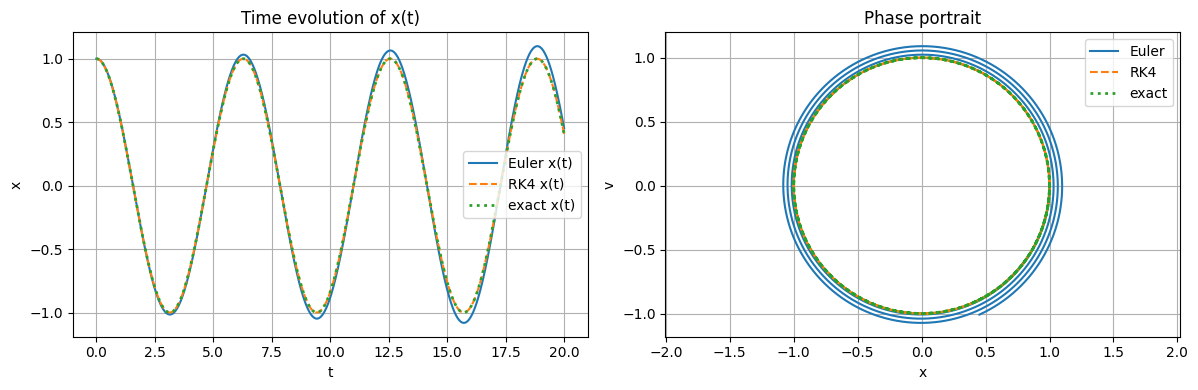

20秒後の真値 x = 0.40808206181339196
20秒後のオイラー法 x = 0.4516706684410249
20秒後の4次ルンゲクッタ法 x = 0.4080820633292473


In [3]:
import numpy as np
import matplotlib.pyplot as plt


# 単振動の右辺 dx/dt = v
def func_dx(t, x, v, m, k_spring):
    return v


# 単振動の右辺 dv/dt = -(k/m) * x
def func_dv(t, x, v, m, k_spring):
    return -(k_spring / m) * x


# 単振動をオイラー法で解く関数
def euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    v = np.zeros(n_steps + 1)

    x[0] = x0
    v[0] = v0

    for n in range(n_steps):
        # 前問で実装したオイラー法の更新式
        dxdt = func_dx(t[n], x[n], v[n], m, k_spring)
        dvdt = func_dv(t[n], x[n], v[n], m, k_spring)

        x[n + 1] = x[n] + dt * dxdt
        v[n + 1] = v[n] + dt * dvdt

    return t, x, v


# 単振動を4次のルンゲクッタ法で解く関数
def runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    v = np.zeros(n_steps + 1)

    x[0] = x0
    v[0] = v0

    for n in range(n_steps):
        # --- ここから完成させた RK4 の更新式 (dtを含めるヒントの形式) ---
        # 1段目の傾き
        k1x = dt * func_dx(t[n], x[n], v[n], m, k_spring)
        k1v = dt * func_dv(t[n], x[n], v[n], m, k_spring)

        # 2段目の傾き (x と v の両方を k1 の半分だけ進めた位置で評価)
        k2x = dt * func_dx(t[n] + dt / 2.0, x[n] + k1x / 2.0, v[n] + k1v / 2.0, m, k_spring)
        k2v = dt * func_dv(t[n] + dt / 2.0, x[n] + k1x / 2.0, v[n] + k1v / 2.0, m, k_spring)

        # 3段目の傾き (x と v の両方を k2 の半分だけ進めた位置で評価)
        k3x = dt * func_dx(t[n] + dt / 2.0, x[n] + k2x / 2.0, v[n] + k2v / 2.0, m, k_spring)
        k3v = dt * func_dv(t[n] + dt / 2.0, x[n] + k2x / 2.0, v[n] + k2v / 2.0, m, k_spring)

        # 4段目の傾き (x と v の両方を k3 の分だけ丸々進めた位置で評価)
        k4x = dt * func_dx(t[n] + dt, x[n] + k3x, v[n] + k3v, m, k_spring)
        k4v = dt * func_dv(t[n] + dt, x[n] + k3x, v[n] + k3v, m, k_spring)

        # 重み付き平均を用いて次のステップの値を計算 (すでに dt を掛けているので dt / 6 ではなく 1 / 6)
        x[n + 1] = x[n] + (k1x + 2.0 * k2x + 2.0 * k3x + k4x) / 6.0
        v[n + 1] = v[n] + (k1v + 2.0 * k2v + 2.0 * k3v + k4v) / 6.0
        # --- ここまで ---

    return t, x, v


# 解析解 x(t), v(t) を返す関数
def exact_oscillator_x(t, m, k_spring, x0, v0):
    omega = np.sqrt(k_spring / m)
    return x0 * np.cos(omega * t) + (v0 / omega) * np.sin(omega * t)


def exact_oscillator_v(t, m, k_spring, x0, v0):
    omega = np.sqrt(k_spring / m)
    return -x0 * omega * np.sin(omega * t) + v0 * np.cos(omega * t)


# ここから具体的な条件を設定する
m = 1.0
k_spring = 1.0
x0 = 1.0
v0 = 0.0
dt = 0.01
T = 20.0

t_euler, x_euler, v_euler = euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)
t_rk4, x_rk4, v_rk4 = runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)

x_exact = exact_oscillator_x(t_euler, m, k_spring, x0, v0)
v_exact = exact_oscillator_v(t_euler, m, k_spring, x0, v0)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(t_euler, x_euler, label="Euler x(t)")
plt.plot(t_rk4, x_rk4, label="RK4 x(t)", linestyle="dashed")
plt.plot(t_euler, x_exact, label="exact x(t)", linestyle="dotted", linewidth=2)
plt.xlabel("t")
plt.ylabel("x")
plt.title("Time evolution of x(t)")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x_euler, v_euler, label="Euler")
plt.plot(x_rk4, v_rk4, label="RK4", linestyle="dashed")
plt.plot(x_exact, v_exact, label="exact", linestyle="dotted", linewidth=2)
plt.xlabel("x")
plt.ylabel("v")
plt.title("Phase portrait")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

print("20秒後の真値 x =", exact_oscillator_x(T, m, k_spring, x0, v0))
print("20秒後のオイラー法 x =", x_euler[-1])
print("20秒後の4次ルンゲクッタ法 x =", x_rk4[-1])


上のプログラムの補足説明です。

- ルンゲクッタ法では、1ステップの中で右辺を4回計算します。今回は $x$ と $v$ の2成分あるので、合計8回呼び出すことになります
- 相図を見ると、オイラー法では軌道が外側に広がっていくのに対して、ルンゲクッタ法では閉じた円に近いままになるはずです
- 単振動ではエネルギーが保存するので、本来、相図の軌道は閉じていなければなりません。軌道が広がるということは、計算の中でエネルギーが増えてしまっているということです

同じ刻み幅なのに結果が大きく違うのはなぜか、1ステップあたりの計算量とあわせて考えてみてください。

### 2.3 刻み幅を変えて比較する

刻み幅 $\Delta t$ をいくつか変えて、オイラー法とルンゲクッタ法の結果を比べます。

オイラー法は刻み幅が大きいと振幅がどんどん大きくなっていきます。
ルンゲクッタ法が同じ条件でどうなるかを確認してください。

TODO は、2.1 と 2.2 で書いた2つの関数を写すところだけです。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 単振動の右辺 dx/dt = v
def func_dx(t, x, v, m, k_spring):
    return v


# 単振動の右辺 dv/dt = -(k/m) * x
def func_dv(t, x, v, m, k_spring):
    return -(k_spring / m) * x


# 単振動をオイラー法で解く関数
def euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    v = np.zeros(n_steps + 1)

    x[0] = x0
    v[0] = v0

    for n in range(n_steps):
        # 前問で実装したオイラー法の更新式
        dxdt = func_dx(t[n], x[n], v[n], m, k_spring)
        dvdt = func_dv(t[n], x[n], v[n], m, k_spring)

        x[n + 1] = x[n] + dt * dxdt
        v[n + 1] = v[n] + dt * dvdt

    return t, x, v

# 単振動を4次のルンゲクッタ法で解く関数
def runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    v = np.zeros(n_steps + 1)

    x[0] = x0
    v[0] = v0

    for n in range(n_steps):
        # --- ここから完成させた RK4 の更新式 (dtを含めるヒントの形式) ---
        # 1段目の傾き
        k1x = dt * func_dx(t[n], x[n], v[n], m, k_spring)
        k1v = dt * func_dv(t[n], x[n], v[n], m, k_spring)

        # 2段目の傾き (x と v の両方を k1 の半分だけ進めた位置で評価)
        k2x = dt * func_dx(t[n] + dt / 2.0, x[n] + k1x / 2.0, v[n] + k1v / 2.0, m, k_spring)
        k2v = dt * func_dv(t[n] + dt / 2.0, x[n] + k1x / 2.0, v[n] + k1v / 2.0, m, k_spring)

        # 3段目の傾き (x と v の両方を k2 の半分だけ進めた位置で評価)
        k3x = dt * func_dx(t[n] + dt / 2.0, x[n] + k2x / 2.0, v[n] + k2v / 2.0, m, k_spring)
        k3v = dt * func_dv(t[n] + dt / 2.0, x[n] + k2x / 2.0, v[n] + k2v / 2.0, m, k_spring)

        # 4段目の傾き (x と v の両方を k3 の分だけ丸々進めた位置で評価)
        k4x = dt * func_dx(t[n] + dt, x[n] + k3x, v[n] + k3v, m, k_spring)
        k4v = dt * func_dv(t[n] + dt, x[n] + k3x, v[n] + k3v, m, k_spring)

        # 重み付き平均を用いて次のステップの値を計算 (すでに dt を掛けているので dt / 6 ではなく 1 / 6)
        x[n + 1] = x[n] + (k1x + 2.0 * k2x + 2.0 * k3x + k4x) / 6.0
        v[n + 1] = v[n] + (k1v + 2.0 * k2v + 2.0 * k3v + k4v) / 6.0
        # --- ここまで ---

    return t, x, v

# 解析解 x(t), v(t) を返す関数
def exact_oscillator_x(t, m, k_spring, x0, v0):
    omega = np.sqrt(k_spring / m)
    return x0 * np.cos(omega * t) + (v0 / omega) * np.sin(omega * t)


def exact_oscillator_v(t, m, k_spring, x0, v0):
    omega = np.sqrt(k_spring / m)
    return -x0 * omega * np.sin(omega * t) + v0 * np.cos(omega * t)


m = 1.0
k_spring = 1.0
x0 = 1.0
v0 = 0.0
T = 20.0
dt_values = [0.001, 0.01, 0.1]  # 試したい刻み幅のリスト

t_exact = np.linspace(0.0, T, 1000)
x_exact = exact_oscillator_x(t_exact, m, k_spring, x0, v0)
v_exact = exact_oscillator_v(t_exact, m, k_spring, x0, v0)

# 時間変化の比較
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for dt in dt_values:
    t, x, v = euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)
    plt.plot(t, x, label=f"Euler dt={dt}")
plt.plot(t_exact, x_exact, label="exact", linestyle="dashed", color="black")
plt.xlabel("t")
plt.ylabel("x")
plt.title("Euler: time evolution for several dt")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
for dt in dt_values:
    t, x, v = runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)
    plt.plot(t, x, label=f"RK4 dt={dt}")
plt.plot(t_exact, x_exact, label="exact", linestyle="dashed", color="black")
plt.xlabel("t")
plt.ylabel("x")
plt.title("RK4: time evolution for several dt")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# 相図の比較
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for dt in dt_values:
    t, x, v = euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)
    plt.plot(x, v, label=f"Euler dt={dt}")
plt.plot(x_exact, v_exact, label="exact", linestyle="dashed", color="black")
plt.xlabel("x")
plt.ylabel("v")
plt.title("Euler: phase portrait")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
for dt in dt_values:
    t, x, v = runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)
    plt.plot(x, v, label=f"RK4 dt={dt}")
plt.plot(x_exact, v_exact, label="exact", linestyle="dashed", color="black")
plt.xlabel("x")
plt.ylabel("v")
plt.title("RK4: phase portrait")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

考えてみましょう。

- オイラー法で刻み幅を大きくすると、相図の軌道はどうなりましたか。物理的に何がおかしいでしょうか
- ルンゲクッタ法では、どのくらいの刻み幅まで「それらしい」結果になりましたか


### 2.4 いろいろな初期値から相図を描いてみる

相図は、1本の軌道だけを描くよりも、**いろいろな初期状態から出発した軌道をまとめて描く**と、システム全体のふるまいが見えてきます。

ここでは4次のルンゲクッタ法を使い、刻み幅を $\Delta t=0.001$ と細かくして、次の4つの初期値から出発した軌道を同じ図に描きます。
$$
(x(0), v(0)) = (0,\,0),\quad (0.5,\,0),\quad (1.0,\,0),\quad (1.5,\,0)
$$

このうち $(0, 0)$ は、右辺が $\boldsymbol{f}(\boldsymbol{x})=\boldsymbol{0}$ となる **固定点（平衡点）** です。
ばねが自然長のまま静止している状態なので、時間が経っても動きません。
軌道としては原点の1点に重なってしまうので、図では黒い点で示しています。

TODO は、2.2 で書いた関数を写すところだけです。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 単振動の右辺 dx/dt = v
def func_dx(t, x, v, m, k_spring):
    return v


# 単振動の右辺 dv/dt = -(k/m) * x
def func_dv(t, x, v, m, k_spring):
    return -(k_spring / m) * x


# 単振動を4次のルンゲクッタ法で解く関数
def runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    # TODO: 2.2 で書いた関数の中身をここに書き写してください


m = 1.0
k_spring = 1.0
dt = 0.001  # 刻み幅を細かくして、軌道がきれいに閉じることを確かめる
T = 20.0

# (x(0), v(0)) の組を並べたリスト
initial_states = [(0.0, 0.0), (0.5, 0.0), (1.0, 0.0), (1.5, 0.0)]

plt.figure(figsize=(6, 6))

for x0, v0 in initial_states:
    t, x, v = runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T)
    plt.plot(x, v, label=f"x(0)={x0}, v(0)={v0}")

# 固定点 (x, v) = (0, 0) を点で示す
plt.plot([0.0], [0.0], "o", color="black", markersize=9, zorder=5, label="fixed point (0, 0)")

plt.xlabel("x")
plt.ylabel("v")
plt.title("Phase portrait of the harmonic oscillator (RK4)")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

考えてみましょう。

- 4つの軌道はどのような形になりましたか。単振動の運動と関連付けて説明してみましょう
- 固定点のまわりを回り続ける軌道は、固定点に近づくわけでも遠ざかるわけでもありません。
  この固定点は「安定」と呼べるでしょうか
- 初期値 $(1.5,\,0)$ の軌道が通る点と、$(0.5,\,0)$ の軌道が通る点は、何が違うのでしょうか。
  単振動のエネルギーと結びつけて考えてみてください

相図を見ると、方程式を解かなくても「このシステムはこう動く」という見通しが立ちます。
授業の後半では、この見方を使って逆振り子のような非線形システムを調べていきます。

### 2章の答えと解説

<details>
<summary>クリックすると開きます（まずは自分で書いてみてください）</summary>

2.3 と 2.4 は、ここにある2つの関数をそのまま貼り付ければ動きます。
途中で詰まっても、この答えを使って先に進み、グラフと考察には必ず目を通してください。

**2.1 オイラー法**

やることは1次のときと同じで、**更新する変数が2つに増えただけ**です。

気をつける点が1つあります。`x[n+1]` と `v[n+1]` は、**どちらも時刻 $t_n$ の値** `x[n]`, `v[n]` から計算します。
もし `v[n+1]` を先に求めて、それを `x[n+1]` の計算に使うと、別の解法（半陰解法・シンプレクティックオイラー法）になります。
実はそちらのほうが相図はきれいに閉じるのですが、今回のオイラー法とは別物です。

```python
def euler_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    v = np.zeros(n_steps + 1)
    x[0] = x0
    v[0] = v0

    for n in range(n_steps):
        x[n + 1] = x[n] + func_dx(t[n], x[n], v[n], m, k_spring) * dt
        v[n + 1] = v[n] + func_dv(t[n], x[n], v[n], m, k_spring) * dt

    return t, x, v
```

**2.2 4次のルンゲクッタ法**

いちばんの要点は、**$k_2$ を計算するときに $x$ と $v$ の両方を $k_1$ の分だけ進める**ことです。

```python
k2x = dt * func_dx(t[n] + dt / 2, x[n] + k1x / 2, v[n] + k1v / 2, m, k_spring)
```

この行で `v[n] + k1v / 2` を `v[n]` と書いてしまうのがよくある間違いです。
動いてしまうので気づきにくいのですが、精度が4次から落ちます。

`k1x` と `k1v`、`k2x` と `k2v` …… のように、**同じ番号のものは必ずペアで作る**と覚えてください。
$k_3$ は $k_2$ の分だけ、$k_4$ は $k_3$ の分だけ進めた点で評価します。$k_4$ だけは `/2` が付きません。

```python
def runge_kutta_oscillator(func_dx, func_dv, m, k_spring, x0, v0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    v = np.zeros(n_steps + 1)
    x[0] = x0
    v[0] = v0

    for n in range(n_steps):
        k1x = dt * func_dx(t[n], x[n], v[n], m, k_spring)
        k1v = dt * func_dv(t[n], x[n], v[n], m, k_spring)
        k2x = dt * func_dx(t[n] + dt / 2, x[n] + k1x / 2, v[n] + k1v / 2, m, k_spring)
        k2v = dt * func_dv(t[n] + dt / 2, x[n] + k1x / 2, v[n] + k1v / 2, m, k_spring)
        k3x = dt * func_dx(t[n] + dt / 2, x[n] + k2x / 2, v[n] + k2v / 2, m, k_spring)
        k3v = dt * func_dv(t[n] + dt / 2, x[n] + k2x / 2, v[n] + k2v / 2, m, k_spring)
        k4x = dt * func_dx(t[n] + dt, x[n] + k3x, v[n] + k3v, m, k_spring)
        k4v = dt * func_dv(t[n] + dt, x[n] + k3x, v[n] + k3v, m, k_spring)
        x[n + 1] = x[n] + (k1x + 2 * k2x + 2 * k3x + k4x) / 6
        v[n + 1] = v[n] + (k1v + 2 * k2v + 2 * k3v + k4v) / 6

    return t, x, v
```

</details>

## 3. ローレンツモデルとカオス

ここからは、少し変わったふるまいをする3次のシステムを扱います。

ローレンツモデルは、大気の対流を大幅に単純化して作られた次の方程式です。
$$
\frac{dx}{dt}=\sigma(y-x), \qquad
\frac{dy}{dt}=x(\rho-z)-y, \qquad
\frac{dz}{dt}=xy-\beta z
$$

右辺に $xz$ や $xy$ という項があるので、これは **非線形** のシステムです。
状態変数は $(x, y, z)$ の3つなので、相空間は3次元になります。

$\sigma=10$, $\rho=28$, $\beta=8/3$ のとき、このシステムは **カオス** と呼ばれるふるまいを示します。
発散もしないし、1点にも落ち着かないし、同じ軌道を繰り返すこともない、という状態です。

解析解は書けません。数値計算でしか調べられない例の代表格です。

### 3.1 4次のルンゲクッタ法で解いてみる

変数が3つに増えましたが、やることは2.2 とまったく同じです。
$k_1$ から $k_4$ を $x$, $y$, $z$ の3成分それぞれについて計算します。

ここでも、$k_2$ を求めるときには **3成分すべてを $k_1$ の分だけ進めた点** で右辺を評価します。

TODO は関数の中の for 文 1 か所です。2.2 で書いた式を3成分に増やすだけです。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# ローレンツモデルの右辺
def func_dx(t, x, y, z, sigma, rho, beta):
    return sigma * (y - x)


def func_dy(t, x, y, z, sigma, rho, beta):
    return x * (rho - z) - y


def func_dz(t, x, y, z, sigma, rho, beta):
    return x * y - beta * z


# ローレンツモデルを4次のルンゲクッタ法で解く関数
def runge_kutta_lorenz(func_dx, func_dy, func_dz, sigma, rho, beta, x0, y0, z0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    y = np.zeros(n_steps + 1)
    z = np.zeros(n_steps + 1)

    x[0] = x0
    y[0] = y0
    z[0] = z0

    for n in range(n_steps):
        # TODO: 4次のルンゲクッタ法で x[n+1], y[n+1], z[n+1] を計算してください
        # ヒント: まず k1x, k1y, k1z を計算します
        #         k2x = dt * func_dx(t[n] + dt / 2, x[n] + k1x / 2, y[n] + k1y / 2, z[n] + k1z / 2, sigma, rho, beta)
        #         のように、3成分すべてを進めた点で右辺を評価します
        #         k3, k4 も同じ要領で計算し、最後に 1/6 (k1 + 2 k2 + 2 k3 + k4) で更新します


    return t, x, y, z


# ここから具体的な条件を設定する
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0

x0 = 1.0
y0 = 1.0
z0 = 1.0
dt = 0.005
T = 50.0

t, x, y, z = runge_kutta_lorenz(func_dx, func_dy, func_dz, sigma, rho, beta, x0, y0, z0, dt, T)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(t, x)
plt.xlabel("t")
plt.ylabel("x")
plt.title("Time evolution of x(t)")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(x, z, linewidth=0.5)
plt.xlabel("x")
plt.ylabel("z")
plt.title("Phase portrait (x-z plane)")
plt.grid(True)

plt.tight_layout()
plt.show()

# 3次元の相空間で軌道を描いてみる
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.plot(x, y, z, linewidth=0.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Lorenz attractor")
plt.show()

上のプログラムの補足説明です。

- `fig.add_subplot(projection="3d")` とすると、3次元のグラフが描けます
- `linewidth=0.5` としているのは、軌道が何度も重なるので線を細くして見やすくするためです

うまく描けると、蝶の羽のような形（ローレンツアトラクター）が出てきます。

ここで $x(t)$ のグラフを見てください。

- 値は発散せず、ある範囲に収まり続けています
- しかし1点に落ち着くわけでも、同じ周期を繰り返すわけでもありません
- 2つの「羽」の間を、不規則に行き来しています

これがカオスと呼ばれるふるまいです。

### 3.2 初期値をほんの少しだけ変えてみる

カオスのいちばん重要な性質は、**初期値鋭敏性** です。

初期値をごくわずかに変えただけで、時間が経つと結果がまったく違うものになります。
ここでは $x(0)$ だけを $10^{-8}$ ずらした2つの計算を比べてみましょう。

$10^{-8}$ は、たとえば測定誤差や単精度の丸め誤差くらいの大きさです。

TODO は、3.1 で書いた関数を写すところだけです。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# ローレンツモデルの右辺
def func_dx(t, x, y, z, sigma, rho, beta):
    return sigma * (y - x)


def func_dy(t, x, y, z, sigma, rho, beta):
    return x * (rho - z) - y


def func_dz(t, x, y, z, sigma, rho, beta):
    return x * y - beta * z


# ローレンツモデルを4次のルンゲクッタ法で解く関数
def runge_kutta_lorenz(func_dx, func_dy, func_dz, sigma, rho, beta, x0, y0, z0, dt, T):
    # TODO: 3.1 で書いた関数の中身をここに書き写してください


sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0

dt = 0.005
T = 50.0

# 2つの初期値を用意する。違いは x(0) の 1e-8 だけ
t_a, x_a, y_a, z_a = runge_kutta_lorenz(func_dx, func_dy, func_dz, sigma, rho, beta, 1.0, 1.0, 1.0, dt, T)
t_b, x_b, y_b, z_b = runge_kutta_lorenz(func_dx, func_dy, func_dz, sigma, rho, beta, 1.0 + 1e-8, 1.0, 1.0, dt, T)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(t_a, x_a, label="x(0) = 1.0")
plt.plot(t_b, x_b, label="x(0) = 1.0 + 1e-8", linestyle="dashed")
plt.xlabel("t")
plt.ylabel("x")
plt.title("Two trajectories from almost the same initial state")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.semilogy(t_a, np.abs(x_a - x_b) + 1e-18)
plt.xlabel("t")
plt.ylabel("|difference of x|")
plt.title("Growth of the initial difference")
plt.grid(True, which="both")

plt.tight_layout()
plt.show()

右のグラフは、2つの解の差の絶対値を縦軸を対数にして描いたものです。

- 最初の差は $10^{-8}$ しかありません
- 片対数グラフで差がほぼ直線的に増えていれば、差が **指数関数的に** 大きくなっているということです
- ある時刻を過ぎると、差は $10$ 前後で頭打ちになって、あとは不規則に振れるだけになります。
  これは $x$ の動く範囲（およそ $-18$ から $19$）と同じくらいの大きさで、「2つの解はもう完全に無関係」という意味です

考えてみましょう。

- 左のグラフで、2つの解が「目で見て区別できる」ようになるのはおおよそ何秒後でしょうか
- 初期値の差を $10^{-12}$ に小さくすると、区別できるようになる時刻はどれだけ先に延びるでしょうか。実際に変えて確かめてみてください
- 天気予報が数週間先まで当たらないことと、この結果はどう関係するでしょうか

カオスを含むシステムでは、個々の軌道を長時間にわたって正確に追うことは原理的にできません。
一方で、軌道が描く全体の形（アトラクター）は、初期値を変えても同じものが現れます。
シミュレーション結果のどこを信じてよいかは、対象によって変わりえます。

### 3章の答えと解説

<details>
<summary>クリックすると開きます（まずは自分で書いてみてください）</summary>

3.2 は、ここにある関数をそのまま貼り付ければ動きます。

**3.1 ローレンツモデルを4次のルンゲクッタ法で解く**

2.2 とまったく同じ構造で、成分が2つから3つに増えただけです。

ここでも要点は同じで、**$k_2$ を計算するときに $x$, $y$, $z$ の3つとも $k_1$ の分だけ進める**ことです。
たとえば `k2y` を求めるのに `k1x` と `k1z` が必要になります。
自分の成分だけを進めてしまうと、グラフはそれらしく出るのに精度が落ちます。

もう1つ注意したいのが**更新の順番**です。
`x[n+1]` を先に確定させてしまうと、`y[n+1]` の計算でそれを使ってしまいそうになります。
$k_1 \sim k_4$ をすべて計算し終えてから、最後に3成分をまとめて更新してください。

```python
def runge_kutta_lorenz(func_dx, func_dy, func_dz, sigma, rho, beta, x0, y0, z0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    y = np.zeros(n_steps + 1)
    z = np.zeros(n_steps + 1)
    x[0] = x0
    y[0] = y0
    z[0] = z0

    for n in range(n_steps):
        k1x = dt * func_dx(t[n], x[n], y[n], z[n], sigma, rho, beta)
        k1y = dt * func_dy(t[n], x[n], y[n], z[n], sigma, rho, beta)
        k1z = dt * func_dz(t[n], x[n], y[n], z[n], sigma, rho, beta)
        k2x = dt * func_dx(t[n] + dt / 2, x[n] + k1x / 2, y[n] + k1y / 2, z[n] + k1z / 2, sigma, rho, beta)
        k2y = dt * func_dy(t[n] + dt / 2, x[n] + k1x / 2, y[n] + k1y / 2, z[n] + k1z / 2, sigma, rho, beta)
        k2z = dt * func_dz(t[n] + dt / 2, x[n] + k1x / 2, y[n] + k1y / 2, z[n] + k1z / 2, sigma, rho, beta)
        k3x = dt * func_dx(t[n] + dt / 2, x[n] + k2x / 2, y[n] + k2y / 2, z[n] + k2z / 2, sigma, rho, beta)
        k3y = dt * func_dy(t[n] + dt / 2, x[n] + k2x / 2, y[n] + k2y / 2, z[n] + k2z / 2, sigma, rho, beta)
        k3z = dt * func_dz(t[n] + dt / 2, x[n] + k2x / 2, y[n] + k2y / 2, z[n] + k2z / 2, sigma, rho, beta)
        k4x = dt * func_dx(t[n] + dt, x[n] + k3x, y[n] + k3y, z[n] + k3z, sigma, rho, beta)
        k4y = dt * func_dy(t[n] + dt, x[n] + k3x, y[n] + k3y, z[n] + k3z, sigma, rho, beta)
        k4z = dt * func_dz(t[n] + dt, x[n] + k3x, y[n] + k3y, z[n] + k3z, sigma, rho, beta)
        x[n + 1] = x[n] + (k1x + 2 * k2x + 2 * k3x + k4x) / 6
        y[n + 1] = y[n] + (k1y + 2 * k2y + 2 * k3y + k4y) / 6
        z[n + 1] = z[n] + (k1z + 2 * k2z + 2 * k3z + k4z) / 6

    return t, x, y, z
```

</details>

## 4. 応用課題: ばねダンパ系のステップ応答

余裕のある人は、減衰のある2次系も解いてみましょう。
制御工学で扱う伝達関数と、数値シミュレーションのつながりが見える例です。

質量・ばね・ダンパからなる系に、$t\ge 0$ で一定の力 $u=1$ を加えます。
$$
m\ddot{x}+c\dot{x}+kx=u(t), \qquad u(t)=\begin{cases}1 & t\ge 0\\ 0 & t<0\end{cases}
$$

$m=k=1$, $c=2$（臨界減衰）の場合、解析的には
$$
x(t)=1-e^{-t}(1+t)
$$
となることが知られています。初期値は $x(0)=\dot{x}(0)=0$ です。

これを数値的に解いて、解析解と一致するか確かめてください。
相図も描いて、固定点 $(x, v)=(1, 0)$ に収束していく様子を確認しましょう。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# ばねダンパ系の右辺 dx/dt = v
def func_dx(t, x, v, m, c, k_spring, u):
    return v


# ばねダンパ系の右辺 dv/dt = (u - c*v - k*x) / m
def func_dv(t, x, v, m, c, k_spring, u):
    # TODO: 運動方程式 m x'' + c x' + k x = u を dv/dt について解いた形を書いてください


# ばねダンパ系を4次のルンゲクッタ法で解く関数
def runge_kutta_damped(func_dx, func_dv, m, c, k_spring, u, x0, v0, dt, T):
    # TODO: 2.2 のルンゲクッタ法を参考に書いてください
    #       引数が増えているので、右辺を呼び出すときの渡し方に注意してください


# 解析解（m = k = 1, c = 2, u = 1, x(0) = v(0) = 0 のとき）
def exact_step_response(t):
    return 1.0 - np.exp(-t) * (1.0 + t)


m = 1.0
c = 2.0
k_spring = 1.0
u = 1.0
x0 = 0.0
v0 = 0.0
dt = 0.01
T = 10.0

t, x, v = runge_kutta_damped(func_dx, func_dv, m, c, k_spring, u, x0, v0, dt, T)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(t, x, label="RK4 x(t)")
plt.plot(t, exact_step_response(t), label="exact", linestyle="dashed")
plt.xlabel("t")
plt.ylabel("x")
plt.title("Step response of the damped system")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, v)
plt.plot([1.0], [0.0], "o", label="fixed point (1, 0)")
plt.xlabel("x")
plt.ylabel("v")
plt.title("Phase portrait")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

print("10秒後の真値 =", exact_step_response(T))
print("10秒後の4次ルンゲクッタ法 =", x[-1])

### 4章の答えと解説

<details>
<summary>クリックすると開きます（まずは自分で書いてみてください）</summary>

ここまでと違い、引数が増えています。右辺を呼び出すときの渡し方に気をつけてください。

**右辺 dv/dt**

運動方程式 $m\ddot{x}+c\dot{x}+kx=u$ を $\ddot{x}$ について解くだけです。
$$
\ddot{x}=\frac{u-c\dot{x}-kx}{m}
$$
プログラムの中では $\dot{x}$ が `v`、ばね定数が `k_spring` です。$m$ で割り忘れないようにしてください。

```python
def func_dv(t, x, v, m, c, k_spring, u):
    return (u - c * v - k_spring * x) / m
```

**4次のルンゲクッタ法**

中身は 2.2 とまったく同じです。違うのは、右辺に渡す引数が `m, k_spring` から `m, c, k_spring, u` に増えたことだけです。

2.2 からコピーしてきた場合は、`func_dx(...)` と `func_dv(...)` の引数をすべて直す必要があります。
1か所でも直し忘れると `TypeError` が出ます。エラーメッセージに出てくる行番号を見て探してください。

```python
def runge_kutta_damped(func_dx, func_dv, m, c, k_spring, u, x0, v0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1)
    v = np.zeros(n_steps + 1)
    x[0] = x0
    v[0] = v0

    for n in range(n_steps):
        k1x = dt * func_dx(t[n], x[n], v[n], m, c, k_spring, u)
        k1v = dt * func_dv(t[n], x[n], v[n], m, c, k_spring, u)
        k2x = dt * func_dx(t[n] + dt / 2, x[n] + k1x / 2, v[n] + k1v / 2, m, c, k_spring, u)
        k2v = dt * func_dv(t[n] + dt / 2, x[n] + k1x / 2, v[n] + k1v / 2, m, c, k_spring, u)
        k3x = dt * func_dx(t[n] + dt / 2, x[n] + k2x / 2, v[n] + k2v / 2, m, c, k_spring, u)
        k3v = dt * func_dv(t[n] + dt / 2, x[n] + k2x / 2, v[n] + k2v / 2, m, c, k_spring, u)
        k4x = dt * func_dx(t[n] + dt, x[n] + k3x, v[n] + k3v, m, c, k_spring, u)
        k4v = dt * func_dv(t[n] + dt, x[n] + k3x, v[n] + k3v, m, c, k_spring, u)
        x[n + 1] = x[n] + (k1x + 2 * k2x + 2 * k3x + k4x) / 6
        v[n + 1] = v[n] + (k1v + 2 * k2v + 2 * k3v + k4v) / 6

    return t, x, v
```

</details>

## 5. 応用課題: 逆振り子の反り返りと安定化

第6回「モデル化の基礎」で扱った、空飛ぶ消火ホースの例をシミュレーションしてみましょう。

ホースの先端から水を噴くと、その反力でホースが**反り返って**しまいました。
この現象を、根元が自由に回る **倒立振り子** として単純化したのが次のモデルです。

長さ $l$ の棒の先に質量 $m$ の質点があり、$\theta$ は水平方向から測った棒の角度です。
噴射反力 $F$ が棒に垂直にかかり、根元にはダンパ $d$ があります。
$$
m l^{2}\ddot{\theta}= l F - m g l\cos\theta - d\dot{\theta}, \qquad (F \ge 0)
$$
右辺は順に、**噴射力のトルク**、**重力のトルク**、**ダンパによる散逸** です。
状態変数は $(\theta, \dot{\theta})$ の2つなので、これも2次のシステムです。

固定点（$\ddot{\theta}=\dot{\theta}=0$）は
$$
m g\cos\theta^{*} = F
$$
を満たす $\theta^{*}$ です。$\cos\theta^{*}\le 1$ なので、
**$F > mg$ のときは固定点がそもそも存在しません。**
このとき右辺の第1項と第2項は打ち消し合えず、棒は回り続けます。これが「反り返る」状態です。

以下では、第6回の資料と同じ数値例を使います。
$$
m=1\ \mathrm{kg},\quad l=1\ \mathrm{m},\quad g=9.8\ \mathrm{m/s^2},\quad d=1\ \mathrm{Nms/rad},\quad F=15\ \mathrm{N}
$$
$F=15 > mg=9.8$ なので、このままでは固定点がありません。

### 5.1 反り返る様子を相図で見る

いくつかの初期角度から出発させて、横軸 $\theta$、縦軸 $\dot{\theta}$ の相図を描きます。

TODO は2か所です。

1. `func_domega`: 運動方程式を $\ddot{\theta}$ について解いた形を書く
2. `runge_kutta_pendulum`: 2.2 のルンゲクッタ法を、$(x, v)$ から $(\theta, \omega)$ に読み替えて書く

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 角度の時間変化 dtheta/dt = omega
def func_dtheta(t, theta, omega, m, l, g, d, F):
    return omega


# 角速度の時間変化 domega/dt
def func_domega(t, theta, omega, m, l, g, d, F):
    # TODO: 運動方程式 m l^2 theta'' = l F - m g l cos(theta) - d theta'
    #       を theta'' について解いた形を書いてください
    # ヒント: cos は np.cos() で計算できます


# 逆振り子を4次のルンゲクッタ法で解く関数
def runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, theta0, omega0, dt, T):
    # TODO: 2.2 のルンゲクッタ法を参考に書いてください
    #       位置 x と速度 v が、角度 theta と角速度 omega に変わっただけです
    #       引数が増えているので、右辺を呼び出すときの渡し方に注意してください


# ここから具体的な条件を設定する
m = 1.0  # 質量 [kg]
l = 1.0  # 長さ [m]
g = 9.8  # 重力加速度 [m/s^2]
d = 1.0  # ダンパ係数 [Nms/rad]
F = 15.0  # 噴射反力 [N]

dt = 0.001
T = 2.0

# いくつかの初期角度から出発させる（初期角速度はどれも 0）
initial_angles = [-0.5, 0.0, 0.5, 1.0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for theta0 in initial_angles:
    t, theta, omega = runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, theta0, 0.0, dt, T)
    plt.plot(t, theta, label=f"theta(0)={theta0}")
plt.xlabel("t [s]")
plt.ylabel("theta [rad]")
plt.title("Time evolution without the fix (F > mg)")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
for theta0 in initial_angles:
    t, theta, omega = runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, theta0, 0.0, dt, T)
    plt.plot(theta, omega, label=f"theta(0)={theta0}")
plt.xlabel("theta [rad]")
plt.ylabel("omega [rad/s]")
plt.title("Phase portrait without the fix")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

グラフを見てみましょう。

- $\theta$ は増え続け、止まるところがありません。棒が一方向に回り続けている状態です
- $\dot{\theta}$ は振動しますが、**0 に戻ることがありません**。噴射力のトルクが重力のトルクに常に勝っているためです
- 相図には、軌道が集まっていく点も、閉じた軌道もありません。どの初期角度から出発しても、右へ流れていくだけです

$F$ を $9.8$ より小さい値（たとえば $F=5$）に変えて実行してみてください。
固定点が現れて、軌道がそこに落ち着くようになるはずです。
ただし、落ち着く先は棒が**下がった**姿勢です。目標である上向きの姿勢ではありません。

### 5.2 外力の向きを一定に保って安定化する

反り返る原因は、**噴射力のトルクと重力のトルクが拮抗できない** ことでした。
棒と一緒に噴射方向も回ってしまうので、棒が倒れても戻す向きの力が出てきません。

そこで、糸で吊るときのように、**外力の向きを重力方向に対して一定に保つ** ことを考えます。
鉛直方向から測った外力の角度を $\psi$ とすると、運動方程式は次のようになります。
$$
m l^{2}\ddot{\theta}= l F\cos(\psi+\theta) - m g l\cos\theta - d\dot{\theta}
$$

$\theta$ が大きくなると $\cos(\psi+\theta)$ が小さくなるので、
**棒が倒れるほど噴射トルクが弱まり、戻す向きのトルクが生まれます。**

固定点の条件は
$$
F\cos(\psi+\theta^{*}) = m g\cos\theta^{*}
$$
です。$\cos(\psi+\theta^{*})=\cos\psi\cos\theta^{*}-\sin\psi\sin\theta^{*}$ を使って整理すると
$$
\tan\theta^{*}=\frac{F\cos\psi - mg}{F\sin\psi}
$$
となり、**どんな $F \ge 0$ に対しても $\theta^{*}$ が求まります**。

$\psi=45^{\circ}$、他のパラメータは 5.1 と同じとして、同じ初期角度から出発させてみましょう。

TODO は 5.1 と同じ2か所です。引数に `psi` が増えていることに注意してください。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 角度の時間変化 dtheta/dt = omega
def func_dtheta(t, theta, omega, m, l, g, d, F, psi):
    return omega


# 角速度の時間変化 domega/dt
def func_domega(t, theta, omega, m, l, g, d, F, psi):
    # TODO: 運動方程式 m l^2 theta'' = l F cos(psi + theta) - m g l cos(theta) - d theta'
    #       を theta'' について解いた形を書いてください


# 逆振り子を4次のルンゲクッタ法で解く関数
def runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, psi, theta0, omega0, dt, T):
    # TODO: 5.1 で書いた関数を、引数 psi が増えた形に直して書いてください


# ここから具体的な条件を設定する
m = 1.0  # 質量 [kg]
l = 1.0  # 長さ [m]
g = 9.8  # 重力加速度 [m/s^2]
d = 1.0  # ダンパ係数 [Nms/rad]
F = 15.0  # 噴射反力 [N]
psi = np.deg2rad(45.0)  # 外力の向き [rad]

dt = 0.001
T = 10.0

# 固定点 theta* を計算する
theta_star = np.arctan((F * np.cos(psi) - m * g) / (F * np.sin(psi)))
print(f"固定点 theta* = {theta_star:.4f} rad = {np.rad2deg(theta_star):.2f} deg")

# 5.1 と同じ初期角度から出発させる
initial_angles = [-0.5, 0.0, 0.5, 1.0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for theta0 in initial_angles:
    t, theta, omega = runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, psi, theta0, 0.0, dt, T)
    plt.plot(t, theta, label=f"theta(0)={theta0}")
plt.axhline(theta_star, color="black", linestyle="dashed", label="theta*")
plt.xlabel("t [s]")
plt.ylabel("theta [rad]")
plt.title("Time evolution with a fixed force direction")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
for theta0 in initial_angles:
    t, theta, omega = runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, psi, theta0, 0.0, dt, T)
    plt.plot(theta, omega, label=f"theta(0)={theta0}")
plt.plot([theta_star], [0.0], "o", color="black", markersize=9, zorder=5, label="fixed point")
plt.xlabel("theta [rad]")
plt.ylabel("omega [rad/s]")
plt.title("Phase portrait with a fixed force direction")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

5.1 の相図と見比べてみましょう。

- どの初期角度から出発しても、軌道は渦を巻きながら固定点 $\theta^{*}$ に吸い込まれていきます
- $\dot{\theta}$ は最後に 0 になります。棒が止まった、ということです
- 5.1 では右へ流れていくだけだったのに対して、ここでは軌道の行き先がはっきり決まっています

考えてみましょう。

- ダンパ $d$ を小さくしていくと、相図はどう変わるでしょうか。$d=0$ ではどうなりますか
- $F$ を大きくすると、固定点 $\theta^{*}$ はどちらに動くでしょうか。式と見比べて確認してください
- $\psi$ を $0^{\circ}$ に近づけると何が起きますか。なぜそうなるのか、トルクの向きで説明してみてください
- 初期角度をもっと大きく（たとえば $\theta(0)=2.5$）すると、固定点に戻ってこない場合があります。
  「安定」という言葉は、どこまでの範囲について言えるのでしょうか

固定点の近くだけを見れば、このシステムは4章で解いたばねダンパ系と同じ形に近似できます。
これを **線形化** といい、第10回以降で詳しく扱います。

### 5章の答えと解説

<details>
<summary>クリックすると開きます（まずは自分で書いてみてください）</summary>

5.1 と 5.2 で合わせて4か所です。ルンゲクッタ法の部分は、2.2 の `x`, `v` を `theta`, `omega` に書き換えただけです。

**5.1 右辺 domega/dt**

$m l^{2}\ddot{\theta}= l F - m g l\cos\theta - d\dot{\theta}$ を $\ddot{\theta}$ について解きます。
$$
\ddot{\theta}=\frac{lF - mgl\cos\theta - d\dot{\theta}}{ml^{2}}
$$
分母が $m l^{2}$（$m l$ ではありません）であること、第1項だけ $\cos\theta$ が付かないことに注意してください。

```python
def func_domega(t, theta, omega, m, l, g, d, F):
    return (l * F - m * g * l * np.cos(theta) - d * omega) / (m * l ** 2)
```

**5.1 4次のルンゲクッタ法**

2.2 と同じ形です。変数名を `theta`, `omega` に変え、右辺に渡す引数を `m, l, g, d, F` にそろえます。
`k1t`（角度）と `k1o`（角速度）のように、**ペアで作る**という点も同じです。

```python
def runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, theta0, omega0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    theta = np.zeros(n_steps + 1)
    omega = np.zeros(n_steps + 1)
    theta[0] = theta0
    omega[0] = omega0

    for n in range(n_steps):
        k1t = dt * func_dtheta(t[n], theta[n], omega[n], m, l, g, d, F)
        k1o = dt * func_domega(t[n], theta[n], omega[n], m, l, g, d, F)
        k2t = dt * func_dtheta(t[n] + dt / 2, theta[n] + k1t / 2, omega[n] + k1o / 2, m, l, g, d, F)
        k2o = dt * func_domega(t[n] + dt / 2, theta[n] + k1t / 2, omega[n] + k1o / 2, m, l, g, d, F)
        k3t = dt * func_dtheta(t[n] + dt / 2, theta[n] + k2t / 2, omega[n] + k2o / 2, m, l, g, d, F)
        k3o = dt * func_domega(t[n] + dt / 2, theta[n] + k2t / 2, omega[n] + k2o / 2, m, l, g, d, F)
        k4t = dt * func_dtheta(t[n] + dt, theta[n] + k3t, omega[n] + k3o, m, l, g, d, F)
        k4o = dt * func_domega(t[n] + dt, theta[n] + k3t, omega[n] + k3o, m, l, g, d, F)
        theta[n + 1] = theta[n] + (k1t + 2 * k2t + 2 * k3t + k4t) / 6
        omega[n + 1] = omega[n] + (k1o + 2 * k2o + 2 * k3o + k4o) / 6

    return t, theta, omega
```

**5.2 右辺 domega/dt**

5.1 の第1項を $lF \to lF\cos(\psi+\theta)$ に変えるだけです。
$$
\ddot{\theta}=\frac{lF\cos(\psi+\theta) - mgl\cos\theta - d\dot{\theta}}{ml^{2}}
$$
`np.cos(psi + theta)` であって `np.cos(psi) + np.cos(theta)` ではありません。

```python
def func_domega(t, theta, omega, m, l, g, d, F, psi):
    return (l * F * np.cos(psi + theta) - m * g * l * np.cos(theta) - d * omega) / (m * l ** 2)
```

**5.2 4次のルンゲクッタ法**

5.1 のものをコピーして、引数に `psi` を足し、右辺の呼び出しすべてに `psi` を渡すだけです。
`def` の行の引数の順番（`..., F, psi, theta0, omega0, dt, T`）を、呼び出し側とそろえてください。

```python
def runge_kutta_pendulum(func_dtheta, func_domega, m, l, g, d, F, psi, theta0, omega0, dt, T):
    n_steps = round(T / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    theta = np.zeros(n_steps + 1)
    omega = np.zeros(n_steps + 1)
    theta[0] = theta0
    omega[0] = omega0

    for n in range(n_steps):
        k1t = dt * func_dtheta(t[n], theta[n], omega[n], m, l, g, d, F, psi)
        k1o = dt * func_domega(t[n], theta[n], omega[n], m, l, g, d, F, psi)
        k2t = dt * func_dtheta(t[n] + dt / 2, theta[n] + k1t / 2, omega[n] + k1o / 2, m, l, g, d, F, psi)
        k2o = dt * func_domega(t[n] + dt / 2, theta[n] + k1t / 2, omega[n] + k1o / 2, m, l, g, d, F, psi)
        k3t = dt * func_dtheta(t[n] + dt / 2, theta[n] + k2t / 2, omega[n] + k2o / 2, m, l, g, d, F, psi)
        k3o = dt * func_domega(t[n] + dt / 2, theta[n] + k2t / 2, omega[n] + k2o / 2, m, l, g, d, F, psi)
        k4t = dt * func_dtheta(t[n] + dt, theta[n] + k3t, omega[n] + k3o, m, l, g, d, F, psi)
        k4o = dt * func_domega(t[n] + dt, theta[n] + k3t, omega[n] + k3o, m, l, g, d, F, psi)
        theta[n + 1] = theta[n] + (k1t + 2 * k2t + 2 * k3t + k4t) / 6
        omega[n + 1] = omega[n] + (k1o + 2 * k2o + 2 * k3o + k4o) / 6

    return t, theta, omega
```

**補足: なぜ固定点に吸い込まれるのか**

固定点のまわりのずれを $\Delta\theta = \theta - \theta^{*}$ として、$\cos$ を1次までで近似すると
$$
\Delta\ddot{\theta} = -c\,\Delta\dot{\theta} - k\,\Delta\theta,
\qquad c=\frac{d}{ml^{2}}>0,
\qquad k=\frac{F}{ml}\sin(\psi+\theta^{*}) - \frac{g}{l}\sin\theta^{*}
$$
という、**4章のばねダンパ系とまったく同じ形**になります。
$c>0$ かつ $k>0$ なら固定点は安定で、これが相図で渦を巻いて吸い込まれていく理由です。

固定点の条件 $F\cos(\psi+\theta^{*})=mg\cos\theta^{*}$ を使って $F$ を消すと
$$
k=\frac{g}{l}\bigl(\cos\theta^{*}\tan(\psi+\theta^{*}) - \sin\theta^{*}\bigr)
$$
とも書けます。$F \ge 0$ で釣り合っている限り $\cos(\psi+\theta^{*})$ と $\cos\theta^{*}$ は同符号なので
$|\psi+\theta^{*}|<\pi/2$ となり、$\psi>0$ であれば $\tan(\psi+\theta^{*})>\tan\theta^{*}$、すなわち $k>0$ です。
**外力の向きを固定しただけで安定になる**のは、このためです。

5.1 のモデルは、これとは違って噴射方向が棒と一緒に回ってしまいます。
同じように線形化すると $k=-\dfrac{g}{l}\sin\theta^{*}$ となり、$\psi$ の項がありません。
$F<mg$ なら固定点 $\cos\theta^{*}=F/(mg)$ が上下に2つ現れますが、
上向きの $\theta^{*}>0$ のほうは $k<0$ で**不安定**です。安定なのは下向きの $\theta^{*}<0$ だけです。
噴射方向を空間に固定することが、上向きの姿勢を保つうえで本質的に効いている、ということです。

</details>

## 6. まとめ

このノートで確認したことを、自分の言葉で書いてみてください。

- 2階の微分方程式を数値的に解くために、何をしたか
- ベクトルになったとき、ルンゲクッタ法のどこに注意が必要だったか
- 単振動で、オイラー法とルンゲクッタ法の相図はどう違ったか。その違いは物理的に何を意味するか
- ローレンツモデルで見た初期値鋭敏性とは、どういう性質か
- カオスを含むシステムで、シミュレーション結果のどこまでを信じてよいか
- 逆振り子が反り返る場合と安定する場合で、相図の何が違ったか